## NB07 — Análise Exploratória de Dados (EDA)

**Entrada:** `data/processed/dataset_ml_clean.csv` — 76.218 linhas × 27 features, 0 NaN (gerado pelo NB06)

**Objetivo:** Compreender a estrutura, distribuições, padrões e anomalias do dataset antes de aplicar os modelos
de detecção de anomalias (Isolation Forest, LOF, One-Class SVM no NB08).
A EDA responde perguntas concretas:
- Qual é o perfil de preço das propostas? Onde estão os desvios mais extremos?
- O volume de licitações varia ao longo do tempo? Existe sazonalidade por mês ou trimestre?
- O ciclo eleitoral se reflete nos dados? Há mais contratações em períodos pré-eleitorais?
- Fornecedores de fora de PE dominam determinadas modalidades ou órgãos?
- Quais modalidades concentram maior risco de anomalia pelo perfil das propostas?

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print('Setup OK')

Setup OK


---
### 1. Carregamento e Visão Geral

Estatísticas gerais: shape, tipos, e tabela
descritiva completa com percentis extremos (P1, P5, P95, P99).

In [28]:
df = pd.read_csv('data/processed/dataset_ml_clean.csv')

print(f'Shape: {df.shape}')
print(f'\nColunas ({len(df.columns)}):')
print(list(df.columns))
print('\nTipos de dados:')
print(df.dtypes)
print(f'\nValores ausentes: {df.isnull().sum().sum()} (esperado: 0)')

df.head()

Shape: (76218, 27)

Colunas (27):
['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_preco_mediana', 'ratio_preco_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_para_eleicao', 'ano_eleitoral', 'pre_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'freq_forn_orgao', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidadeNome', 'porte', 'cnae_fiscal', 'descricao_situacao_cadastral']

Tipos de dados:
orgaoEntidadeCnpj                 int64
anoCompraPncp                     int64
sequencialCompraPncp              int64
numeroItem                        int64
cnpj_forn_norm                    int64
desvio_preco_mediana            float64
ratio_preco_estimado            float64
n_propostas_item                  int64
fornecedor_unico                  int64
ano                               int64
mes                               int64
trimestre    

,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_preco_mediana,ratio_preco_estimado,n_propostas_item,fornecedor_unico,ano,...,tipo_fornecedor,idade_empresa_anos,empresa_nova,freq_forn_orgao,opcao_pelo_mei,opcao_pelo_simples,modalidadeNome,porte,cnae_fiscal,descricao_situacao_cadastral
0,10260222000105,2023,61,1,40230669000194,-0.046105,1.0,2,0,2023,...,1,2.524298,0,1,1,1,3,1,8230001,0
1,402552000126,2022,331,1,33040635000171,0.393626,1.0,2,0,2023,...,1,50.160164,0,1,0,0,3,3,4645101,0
2,10260222000105,2023,60,1,10474760456,0.000000,1.0,1,1,2023,...,0,28.804928,0,1,0,0,3,0,-1,1
3,10260222000105,2023,48,1,47270709000170,0.584158,1.0,2,0,2023,...,1,0.960986,1,1,0,1,3,1,9001902,0
4,10260222000105,2023,52,1,20852792000130,0.000000,1.0,1,1,2023,...,1,8.903491,0,2,0,1,3,1,9001902,0


In [29]:
df.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
orgaoEntidadeCnpj,76218.0,8.156092e+12,9.239763e+12,3.816600e+10,3.480030e+11,3.944290e+11,3.944520e+11,9.773169e+12,1.135814e+13,2.699456e+13,3.587281e+13,4.235748e+13
anoCompraPncp,76218.0,2.023680e+03,4.812236e-01,2.022000e+03,2.023000e+03,2.023000e+03,2.023000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.025000e+03
sequencialCompraPncp,76218.0,3.682143e+03,5.619679e+03,1.000000e+00,1.000000e+00,6.000000e+00,7.000000e+01,5.580000e+02,4.106000e+03,1.560000e+04,2.123600e+04,2.256900e+04
numeroItem,76218.0,5.755190e+01,8.431118e+01,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00,2.400000e+01,7.300000e+01,2.420000e+02,4.140000e+02,5.030000e+02
cnpj_forn_norm,76218.0,2.639993e+13,2.022847e+14,0.000000e+00,0.000000e+00,8.521065e+09,8.778201e+12,2.404646e+13,4.126394e+13,5.350689e+13,7.144367e+13,5.562232e+16
desvio_preco_mediana,76218.0,6.096788e-01,1.592986e+02,-1.000000e+00,-9.008768e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,8.015749e-01,4.396648e+04
ratio_preco_estimado,76218.0,1.322071e-01,7.807258e-01,0.000000e+00,4.478537e-08,1.435660e-04,1.370030e-03,5.978293e-03,4.431273e-02,1.000000e+00,1.000000e+00,2.000000e+02
n_propostas_item,76218.0,1.485581e+00,2.982230e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,1.200000e+01,4.200000e+01
fornecedor_unico,76218.0,8.973864e-01,3.034555e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
ano,76218.0,2.023723e+03,4.473664e-01,2.023000e+03,2.023000e+03,2.023000e+03,2.023000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03


---
### 2. Visão Geral: Cardinalidades e Entidades

- **orgaoEntidadeCnpj**: número de órgãos compradores distintos no dataset
- **cnpj_forn_norm**: número de fornecedores únicos
- **modalidadeNome**: número de modalidades licitatórias presentes
- **cnae_fiscal**: diversidade de setores econômicos dos fornecedores

In [30]:
cardinalidade = pd.DataFrame({
    'unicos': df.nunique(),
    'pct_total': (df.nunique() / len(df) * 100).round(2)
}).sort_values('unicos', ascending=False)

print('Cardinalidade por coluna:')
print(cardinalidade.to_string())

print('\n--- Resumo de entidades ---')
n_orgaos = df['orgaoEntidadeCnpj'].nunique()
n_forn   = df['cnpj_forn_norm'].nunique()
n_contr  = df.groupby(['orgaoEntidadeCnpj','anoCompraPncp','sequencialCompraPncp']).ngroups
print(f'Orgaos compradores:  {n_orgaos:>6,}')
print(f'Fornecedores unicos: {n_forn:>6,}')
print(f'Contratacoes:        {n_contr:>6,}')
print(f'Propostas (linhas):  {len(df):>6,}')

Cardinalidade por coluna:
                              unicos  pct_total
ratio_preco_estimado           62028      81.38
cnpj_forn_norm                  9447      12.39
idade_empresa_anos              7385       9.69
sequencialCompraPncp            4156       5.45
desvio_preco_mediana            3341       4.38
cnae_fiscal                      512       0.67
numeroItem                       503       0.66
dias_para_eleicao                474       0.62
orgaoEntidadeCnpj                103       0.14
freq_forn_orgao                   28       0.04
n_propostas_item                  21       0.03
mes                               12       0.02
dia_semana                         7       0.01
modalidadeNome                     6       0.01
descricao_situacao_cadastral       5       0.01
porte                              4       0.01
trimestre                          4       0.01
anoCompraPncp                      4       0.01
fornecedor_unico                   2       0.00
ano           

---
### 3. Distribuições das Features Numéricas Contínuas

Features numéricas para detecção de anomalias, segundo Araújo:
- **`desvio_preco_mediana`**: desvio percentual do valor proposto em relação à mediana dos
  vencedores do mesmo item. Valor 0 = no mediano; valor 1 = 100% acima; −1 = 100% abaixo.
  Sobrepreços extremos são candidatos diretos a anomalia.
- **`ratio_preco_estimado`**: razão entre o valor proposto e o teto estimado pelo órgão.
  Ratio > 1 indica proposta acima do teto — situação que pode indicar erro ou irregularidade.
- **`idade_empresa_anos`**: idade da empresa na data da proposta. Empresas muito novas em
  contratações de alto valor são sinal clássico de risco.
- **`freq_forn_orgao`**: frequência histórica do fornecedor com o órgão. Valores altos podem
  indicar relacionamento preferencial; valor = 1 indica estreante.
- **`dias_para_eleicao`**: distância em dias para a próxima eleição municipal.

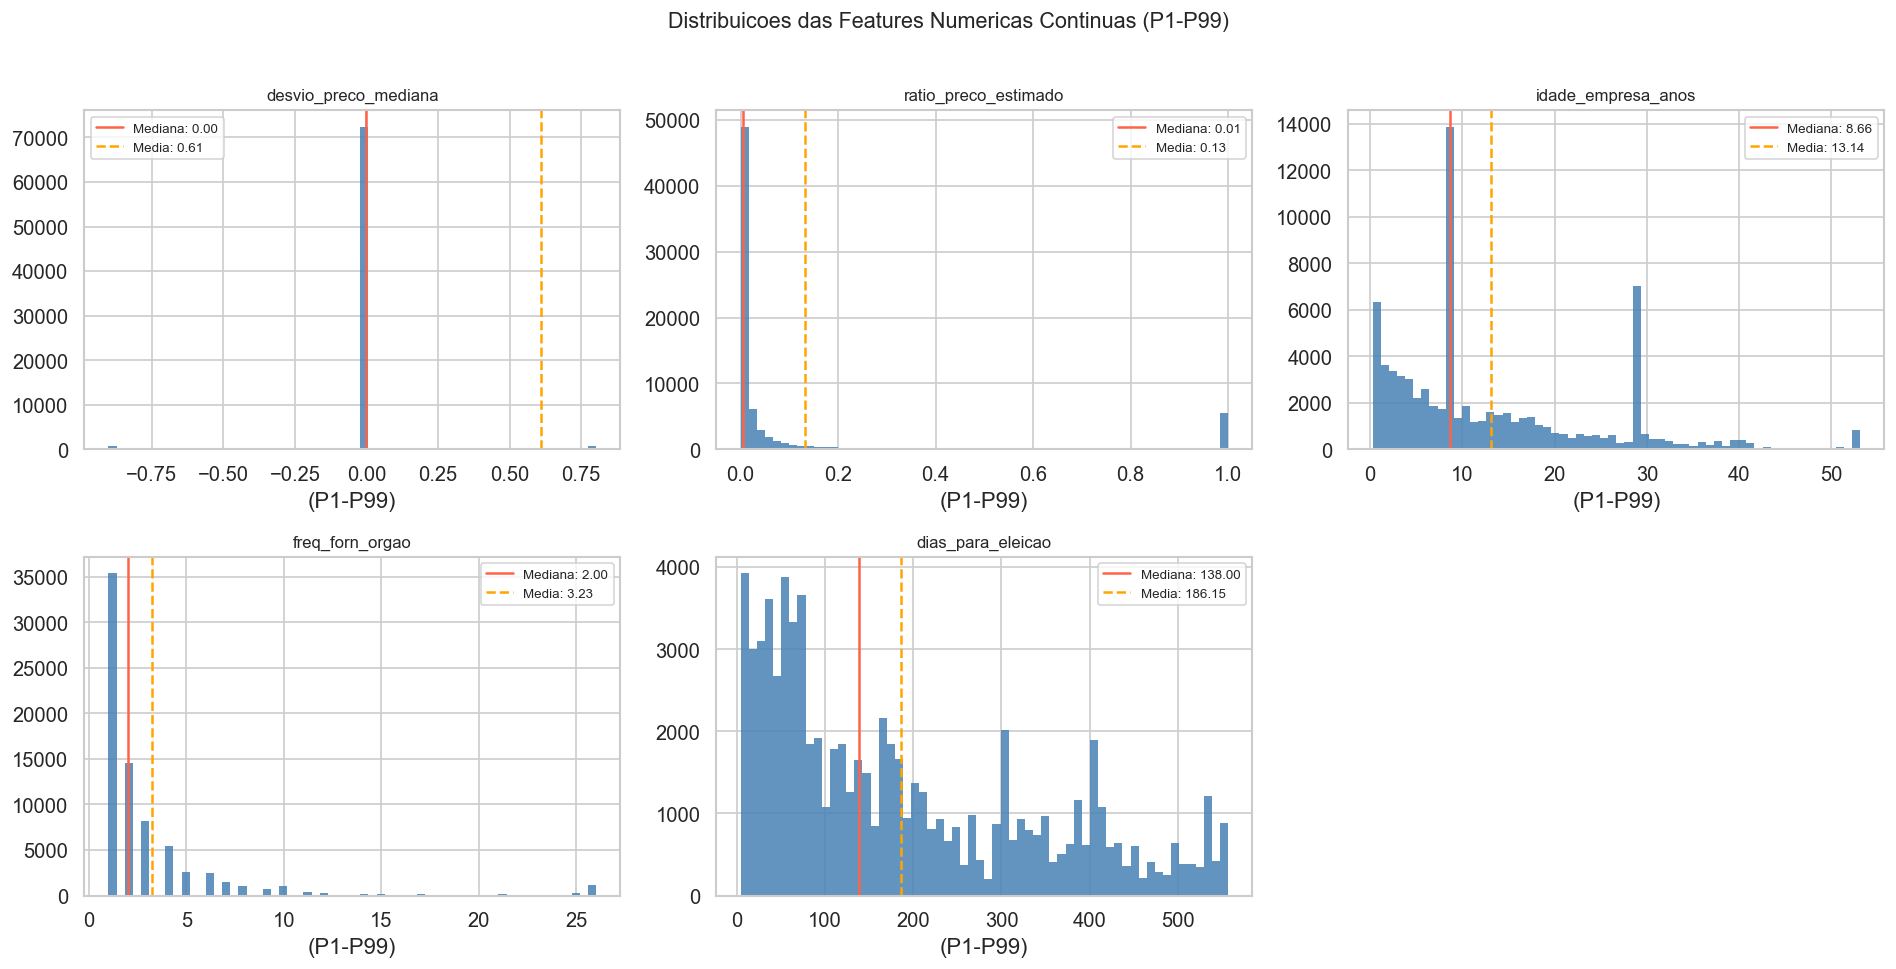

,desvio_preco_mediana,ratio_preco_estimado,idade_empresa_anos,freq_forn_orgao,dias_para_eleicao
count,76218.000,76218.000,76218.000,76218.000,76218.000
mean,0.610,0.132,13.137,3.226,186.154
std,159.299,0.781,11.451,4.679,155.353
min,-1.000,0.000,0.000,1.000,1.000
1%,-0.901,0.000,0.285,1.000,4.000
5%,0.000,0.000,0.780,1.000,13.000
25%,0.000,0.001,4.486,1.000,57.000
50%,0.000,0.006,8.660,2.000,138.000
75%,0.000,0.044,18.938,3.000,305.000
95%,0.000,1.000,33.198,10.000,500.000


In [31]:
numericas = ['desvio_preco_mediana', 'ratio_preco_estimado',
             'idade_empresa_anos', 'freq_forn_orgao', 'dias_para_eleicao']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(numericas):
    data = df[col].dropna()
    p1, p99 = data.quantile(0.01), data.quantile(0.99)
    data_vis = data.clip(p1, p99)
    axes[i].hist(data_vis, bins=60, color='steelblue', edgecolor='none', alpha=0.85)
    med_val = data.median()
    mean_val = data.mean()
    axes[i].axvline(med_val, color='tomato', linewidth=1.5, label=f'Mediana: {med_val:.2f}')
    axes[i].axvline(mean_val, color='orange', linewidth=1.5, linestyle='--', label=f'Media: {mean_val:.2f}')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('(P1-P99)')
    axes[i].legend(fontsize=8)

axes[5].set_visible(False)
plt.suptitle('Distribuicoes das Features Numericas Continuas (P1-P99)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

df[numericas].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).round(3)

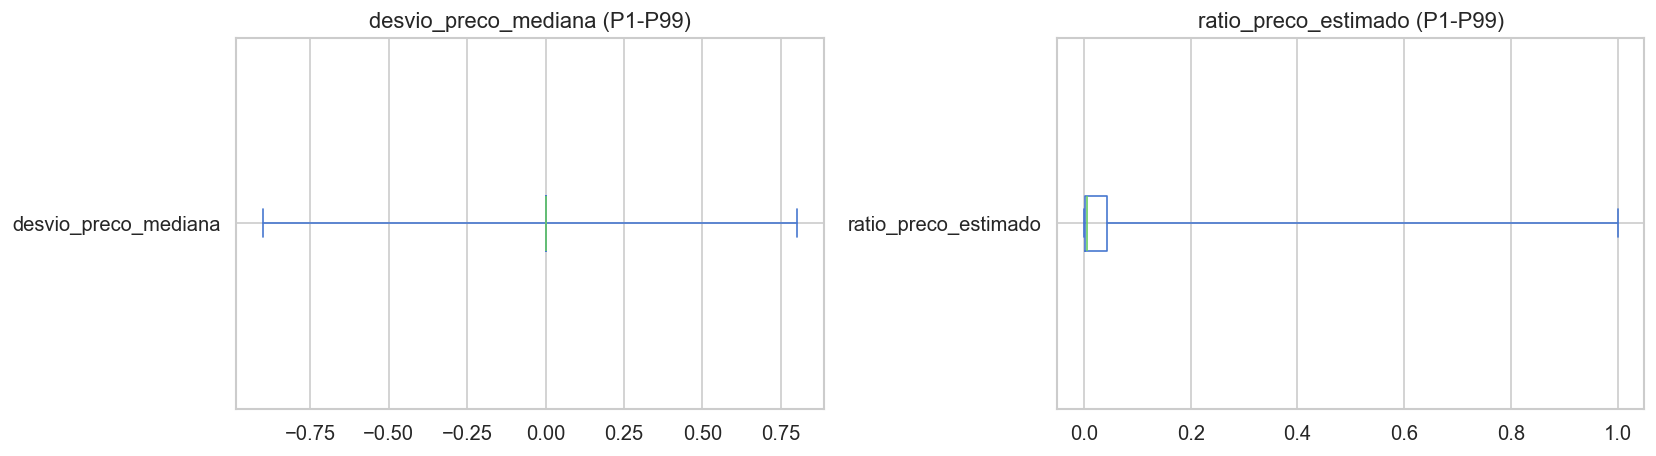

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['desvio_preco_mediana'].plot(kind='box', vert=False, ax=axes[0], whis=[1,99], showfliers=False)
axes[0].set_title('desvio_preco_mediana (P1-P99)')
df['ratio_preco_estimado'].plot(kind='box', vert=False, ax=axes[1], whis=[1,99], showfliers=False)
axes[1].set_title('ratio_preco_estimado (P1-P99)')
plt.tight_layout()
plt.show()

---
### 4. Distribuições das Features Categóricas e Binárias

- **`fornecedor_unico`**: 1 se apenas um vencedor registrado no item (89,7%). Desequilíbrio
  parcialmente artefato da API PNCP (retorna só vencedor).
- **`fornecedor_fora_pe`**: 1 se fornecedor é de outro estado (63,1%).
- **`tipo_fornecedor`**: 1 = pessoa jurídica (91%), 0 = pessoa física (9%).
- **`empresa_nova`**: 1 se empresa com < 1 ano de existência na data da proposta.
- **`porte`**: ordinal — 0=desconhecido, 1=micro, 2=EPP, 3=demais.
- **`modalidadeNome`**: modalidade licitatória (label-encoded no NB06).

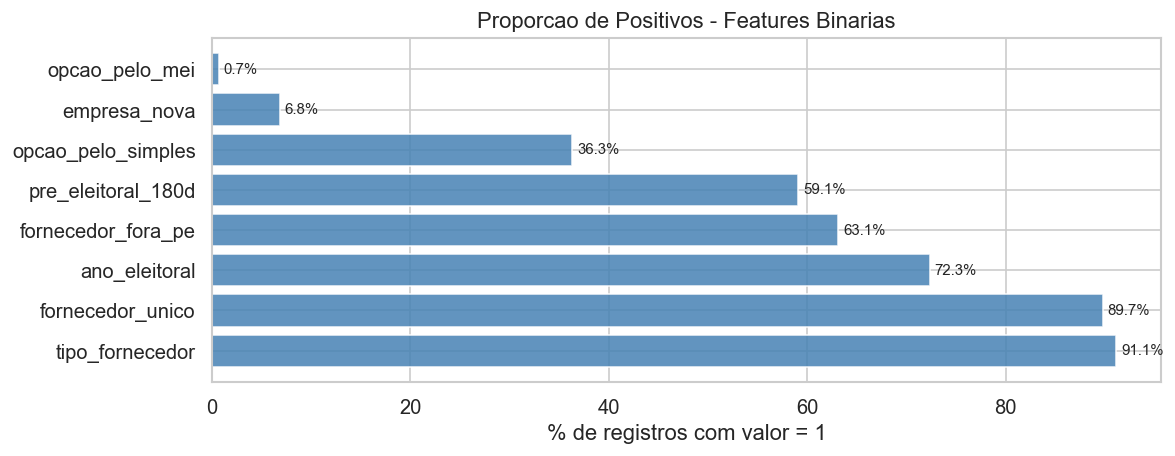

In [33]:
binarias = ['fornecedor_unico', 'fornecedor_fora_pe', 'tipo_fornecedor',
            'empresa_nova', 'ano_eleitoral', 'pre_eleitoral_180d',
            'opcao_pelo_mei', 'opcao_pelo_simples']

prop = df[binarias].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(prop.index, prop.values * 100, color='steelblue', alpha=0.85)
ax.set_xlabel('% de registros com valor = 1')
ax.set_title('Proporcao de Positivos - Features Binarias')
for bar, val in zip(bars, prop.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val*100:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

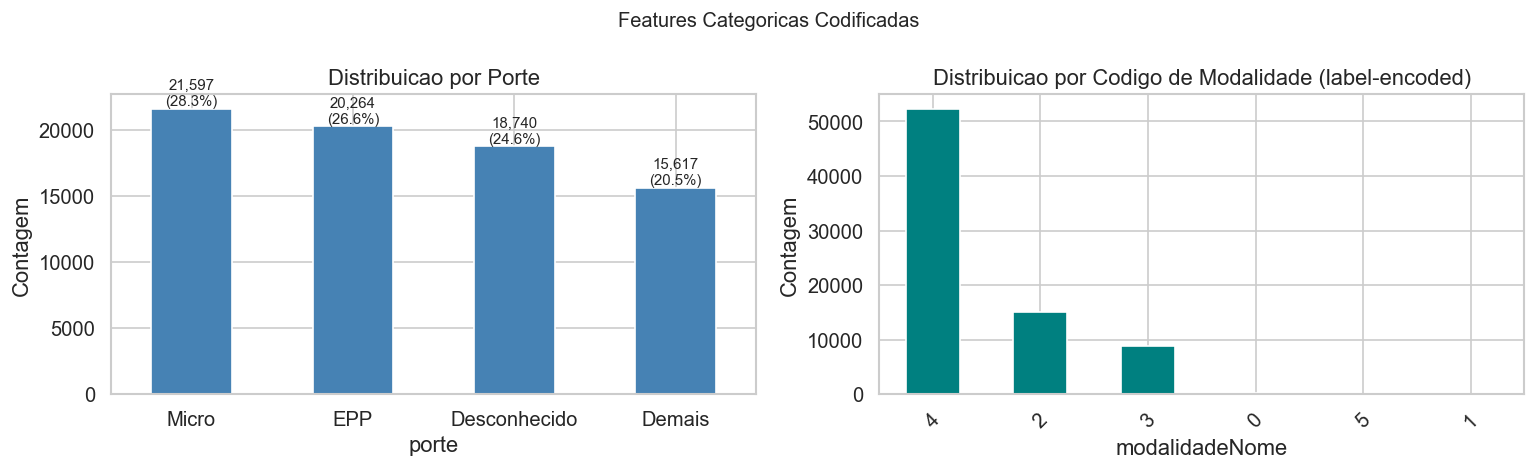

In [34]:
porte_labels = {0: 'Desconhecido', 1: 'Micro', 2: 'EPP', 3: 'Demais'}
porte_counts = df['porte'].map(porte_labels).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

porte_counts.plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Distribuicao por Porte')
axes[0].set_ylabel('Contagem')
for p in axes[0].patches:
    pct = p.get_height() / len(df) * 100
    axes[0].annotate(f'{p.get_height():,.0f}\n({pct:.1f}%)',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=9)

df['modalidadeNome'].value_counts().plot(kind='bar', ax=axes[1], color='teal', rot=45)
axes[1].set_title('Distribuicao por Codigo de Modalidade (label-encoded)')
axes[1].set_ylabel('Contagem')

plt.suptitle('Features Categoricas Codificadas', fontsize=12)
plt.tight_layout()
plt.show()

---
### 5. Análise de Outliers de Preço

Sobrepreços e subpreços extremos são o núcleo da detecção de anomalias em licitações.
Esta seção identifica:

1. **Thresholds de sobrepreço**: proporção de propostas com `desvio_preco_mediana` > 0.5
   (50% acima da mediana), > 1.0 (dobro), > 2.0 (triplo).
2. **Threshold de ratio**: proporção com `ratio_preco_estimado` > 1.0 (acima do teto estimado).
3. **Top 20 outliers**: propostas com os maiores desvios para inspeção manual.
4. **Perfil dos outliers**: distribuição por porte, tipo de fornecedor e perfil de empresa
   — sinaliza quais combinações concentram maior risco.

In [35]:
thresholds_desvio = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
thresholds_ratio  = [1.0, 1.1, 1.5, 2.0]

print('=== desvio_preco_mediana ===')
for t in thresholds_desvio:
    n = (df['desvio_preco_mediana'] > t).sum()
    pct = n / len(df) * 100
    print(f'  > {t}: {n:>8,} propostas ({pct:.2f}%)')

print('\n=== ratio_preco_estimado ===')
for t in thresholds_ratio:
    n = (df['ratio_preco_estimado'] > t).sum()
    pct = n / len(df) * 100
    print(f'  > {t}: {n:>8,} propostas ({pct:.2f}%)')

=== desvio_preco_mediana ===
  > 0.1:    1,552 propostas (2.04%)
  > 0.5:    1,076 propostas (1.41%)
  > 1.0:       47 propostas (0.06%)
  > 2.0:       36 propostas (0.05%)
  > 5.0:       28 propostas (0.04%)
  > 10.0:       21 propostas (0.03%)

=== ratio_preco_estimado ===
  > 1.0:        7 propostas (0.01%)
  > 1.1:        6 propostas (0.01%)
  > 1.5:        4 propostas (0.01%)
  > 2.0:        4 propostas (0.01%)


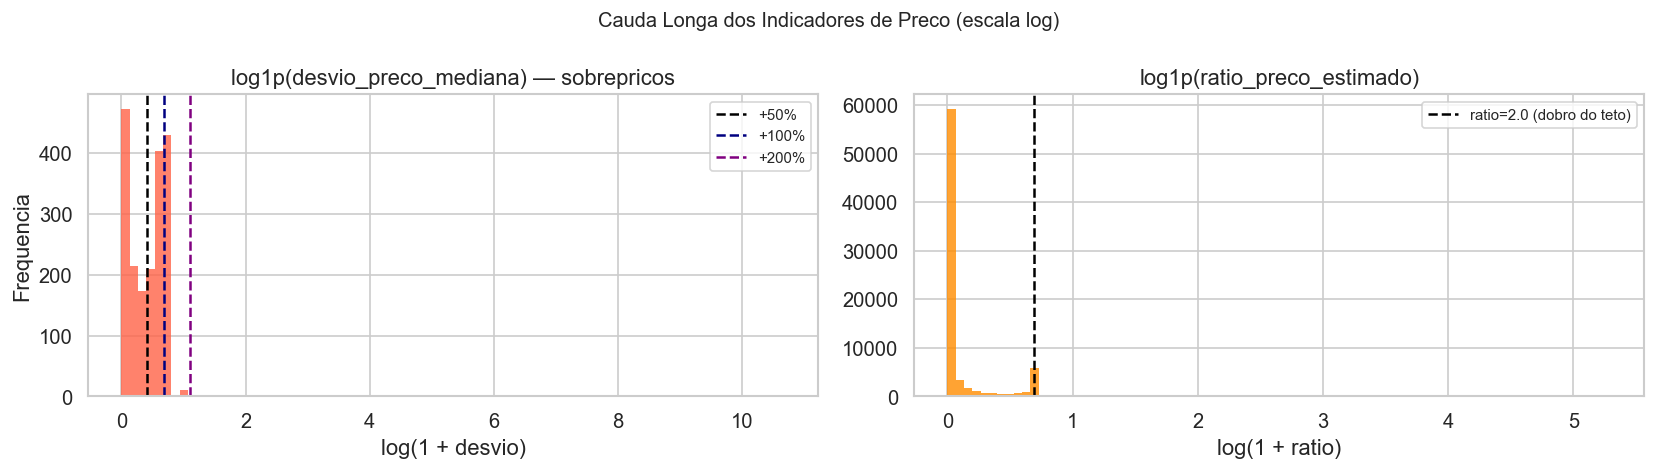

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sobrepreco = df.loc[df['desvio_preco_mediana'] > 0, 'desvio_preco_mediana']
axes[0].hist(np.log1p(sobrepreco), bins=80, color='tomato', alpha=0.8, edgecolor='none')
axes[0].set_title('log1p(desvio_preco_mediana) — sobrepricos')
axes[0].set_xlabel('log(1 + desvio)')
axes[0].set_ylabel('Frequencia')
axes[0].axvline(np.log1p(0.5), color='black', linestyle='--', label='+50%')
axes[0].axvline(np.log1p(1.0), color='navy', linestyle='--', label='+100%')
axes[0].axvline(np.log1p(2.0), color='purple', linestyle='--', label='+200%')
axes[0].legend(fontsize=9)

acima_teto = df.loc[df['ratio_preco_estimado'] > 0, 'ratio_preco_estimado']
axes[1].hist(np.log1p(acima_teto), bins=80, color='darkorange', alpha=0.8, edgecolor='none')
axes[1].set_title('log1p(ratio_preco_estimado)')
axes[1].set_xlabel('log(1 + ratio)')
axes[1].axvline(np.log1p(1.0), color='black', linestyle='--', label='ratio=2.0 (dobro do teto)')
axes[1].legend(fontsize=9)

plt.suptitle('Cauda Longa dos Indicadores de Preco (escala log)', fontsize=12)
plt.tight_layout()
plt.show()

In [37]:
# Top 20 outliers de sobrepreco
cols_top = ['orgaoEntidadeCnpj','anoCompraPncp','sequencialCompraPncp','numeroItem',
            'cnpj_forn_norm','desvio_preco_mediana','ratio_preco_estimado',
            'porte','tipo_fornecedor','empresa_nova','freq_forn_orgao']
outliers_preco = df.nlargest(20, 'desvio_preco_mediana')[cols_top]
print('Top 20 propostas com maior sobrepreco:')
outliers_preco

Top 20 propostas com maior sobrepreco:


,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_preco_mediana,ratio_preco_estimado,porte,tipo_fornecedor,empresa_nova,freq_forn_orgao
12880,24416174000106,2024,2,2,13406686000167,43966.479675,0.223544,3,1,0,1
26704,394452000103,2024,3943,1,7617400403,741.354839,0.933893,0,0,0,2
11369,10767239000145,2022,55,1,33683111000107,526.893463,1.000000,3,1,0,2
2243,10571982000125,2022,98,1,60746948000112,319.618583,1.000000,3,1,0,3
40749,24134488000108,2024,50,1,33683111000107,200.599708,0.929165,3,1,0,1
12879,24416174000106,2024,2,1,13406686000167,198.499876,0.200065,3,1,0,1
40750,24134488000108,2024,50,2,33683111000107,140.778976,0.070835,3,1,0,1
25321,24134488000108,2024,22,1,21643102000103,118.328243,0.948024,1,1,0,1
31446,33781055000135,2024,549,1,2385669000174,87.078867,1.000000,3,1,0,16
2246,10571982000125,2022,100,1,90400888000142,75.375990,1.000000,3,1,0,1


Propostas com desvio > 100%: 47 (0.1%)


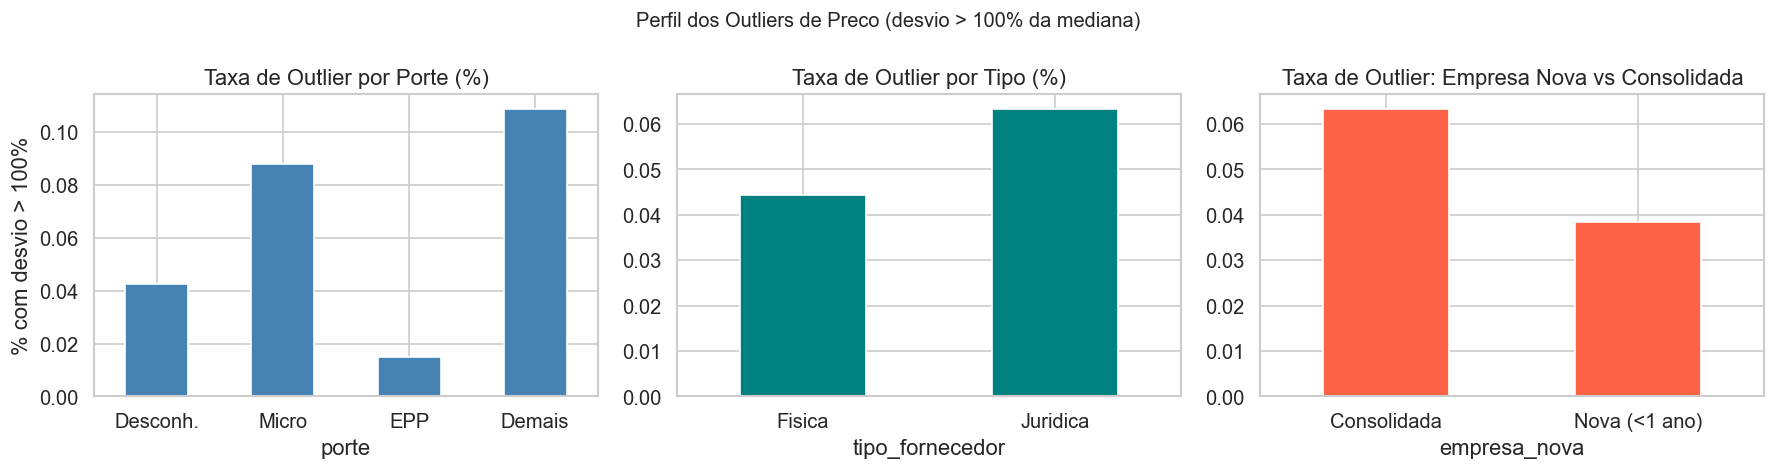

In [38]:
# Perfil dos outliers
df['outlier_preco'] = (df['desvio_preco_mediana'] > 1.0).astype(int)
n_outliers = df['outlier_preco'].sum()
pct_outliers = df['outlier_preco'].mean() * 100
print(f'Propostas com desvio > 100%: {n_outliers:,} ({pct_outliers:.1f}%)')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

porte_map = {0: 'Desconh.', 1: 'Micro', 2: 'EPP', 3: 'Demais'}
taxa_porte = df.groupby('porte')['outlier_preco'].mean() * 100
taxa_porte.index = taxa_porte.index.map(porte_map)
taxa_porte.plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Taxa de Outlier por Porte (%)')
axes[0].set_ylabel('% com desvio > 100%')

taxa_tipo = df.groupby('tipo_fornecedor')['outlier_preco'].mean() * 100
taxa_tipo.index = taxa_tipo.index.map({0: 'Fisica', 1: 'Juridica'})
taxa_tipo.plot(kind='bar', ax=axes[1], color='teal', rot=0)
axes[1].set_title('Taxa de Outlier por Tipo (%)')

taxa_nova = df.groupby('empresa_nova')['outlier_preco'].mean() * 100
taxa_nova.index = taxa_nova.index.map({0: 'Consolidada', 1: 'Nova (<1 ano)'})
taxa_nova.plot(kind='bar', ax=axes[2], color='tomato', rot=0)
axes[2].set_title('Taxa de Outlier: Empresa Nova vs Consolidada')

plt.suptitle('Perfil dos Outliers de Preco (desvio > 100% da mediana)', fontsize=12)
plt.tight_layout()
plt.show()

---
### 6. Sazonalidade Temporal

1. **Ciclo orçamentário**: órgãos públicos tendem a concentrar contratações no final do ano
   (novembro–dezembro) para executar o orçamento aprovado, e no início (fevereiro–março)
   após a aprovação do PPA/LOA.
2. **Ciclo eleitoral**: 2024 é ano eleitoral municipal — esperamos pico de contratações
   no período pré-eleitoral (jan–out/2024).
3. **Efeito dia da semana**: contratações publicadas na sexta-feira têm menor visibilidade
   pública, o que pode facilitar irregularidades.
4. **Transição legal**: aumento acentuado de contratações entre 2023 e 2024 reflete
   a adesão crescente ao novo regime jurídico.

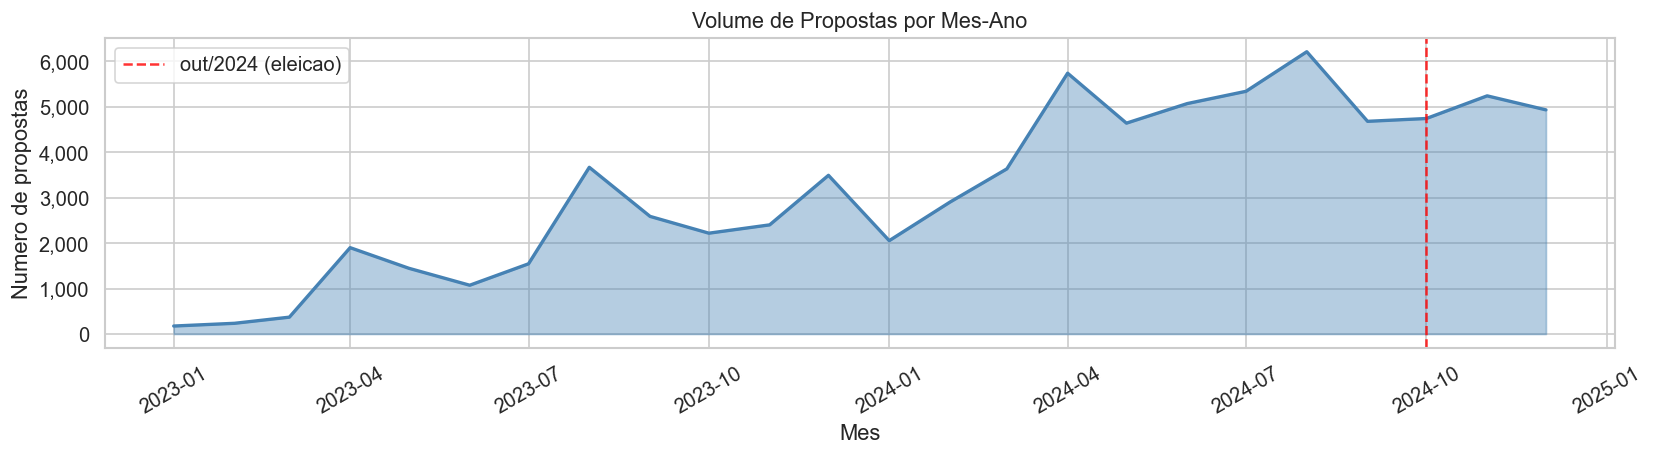

In [39]:
# Série temporal mensal
df['ano_mes'] = pd.to_datetime(df['ano'].astype(str) + '-' + df['mes'].astype(str).str.zfill(2) + '-01')
serie_temporal = df.groupby('ano_mes').size().reset_index(name='n_propostas')

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(serie_temporal['ano_mes'], serie_temporal['n_propostas'], alpha=0.4, color='steelblue')
ax.plot(serie_temporal['ano_mes'], serie_temporal['n_propostas'], color='steelblue', linewidth=2)
ax.axvline(pd.Timestamp('2024-10-01'), color='red', linestyle='--', alpha=0.8, label='out/2024 (eleicao)')
ax.set_title('Volume de Propostas por Mes-Ano', fontsize=13)
ax.set_xlabel('Mes')
ax.set_ylabel('Numero de propostas')
ax.legend()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

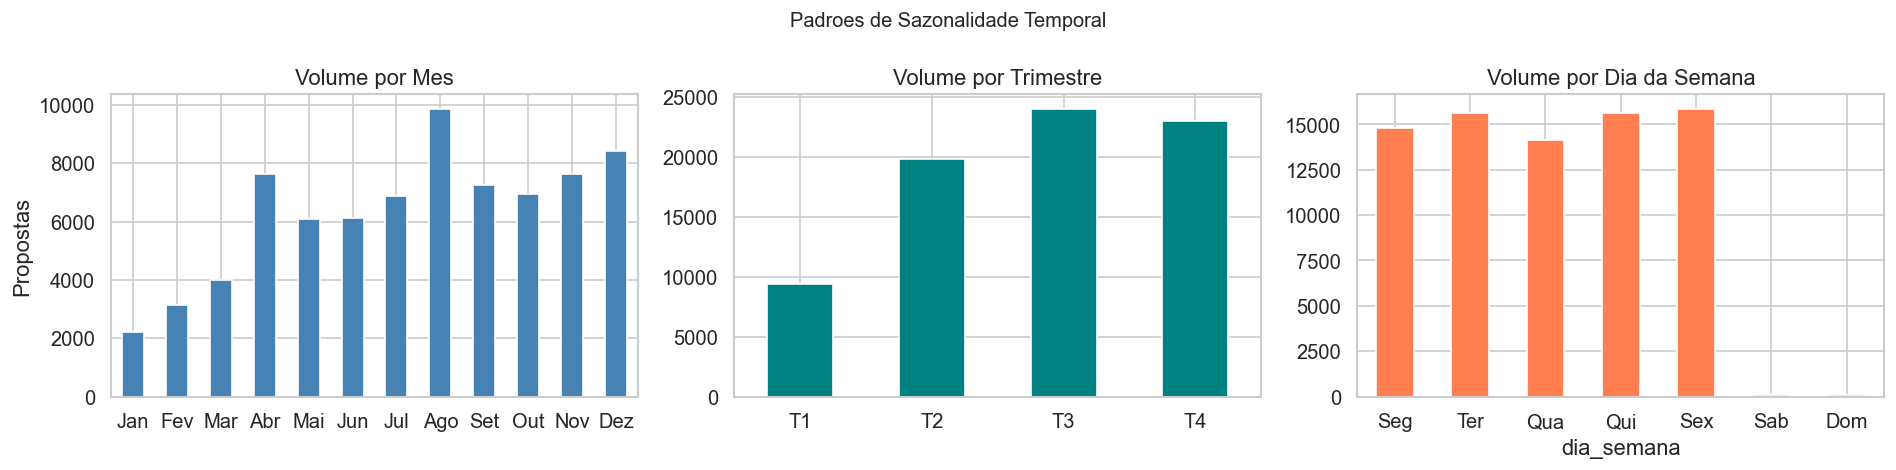

In [40]:
nomes_mes = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

por_mes = df.groupby('mes').size()
por_mes.index = [nomes_mes[m-1] for m in por_mes.index]
por_mes.plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Volume por Mes')
axes[0].set_ylabel('Propostas')

por_tri = df.groupby('trimestre').size()
por_tri.index = ['T' + str(i) for i in por_tri.index]
por_tri.plot(kind='bar', ax=axes[1], color='teal', rot=0)
axes[1].set_title('Volume por Trimestre')

por_dia = df.groupby('dia_semana').size()
dias_nomes = {0:'Seg',1:'Ter',2:'Qua',3:'Qui',4:'Sex',5:'Sab',6:'Dom'}
por_dia.index = por_dia.index.map(dias_nomes)
por_dia.plot(kind='bar', ax=axes[2], color='coral', rot=0)
axes[2].set_title('Volume por Dia da Semana')

plt.suptitle('Padroes de Sazonalidade Temporal', fontsize=12)
plt.tight_layout()
plt.show()

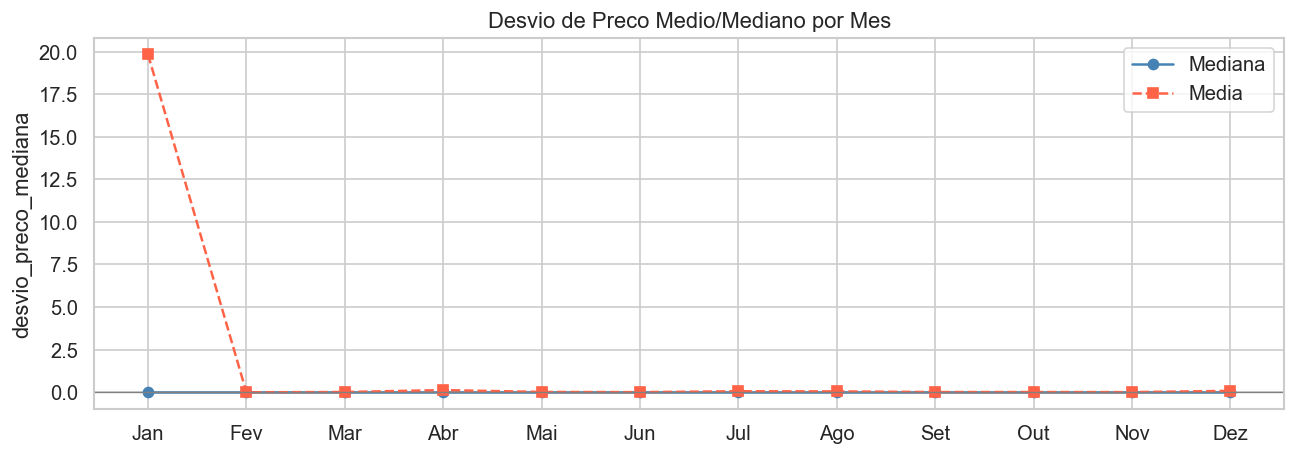

        mean  median       std
Jan  19.8474     0.0  931.6763
Fev  -0.0108     0.0    0.2223
Mar   0.0042     0.0    0.6358
Abr   0.1166     0.0    8.6049
Mai   0.0086     0.0    1.1301
Jun  -0.0036     0.0    0.1528
Jul   0.0496     0.0    2.9591
Ago   0.0402     0.0    3.3092
Set   0.0018     0.0    0.1642
Out   0.0028     0.0    0.2242
Nov  -0.0022     0.0    0.1160
Dez   0.0727     0.0    5.7630


In [41]:
# Desvio de preco medio por mes
desvio_por_mes = df.groupby('mes')['desvio_preco_mediana'].agg(['mean','median','std'])
desvio_por_mes.index = [nomes_mes[m-1] for m in desvio_por_mes.index]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(desvio_por_mes.index, desvio_por_mes['median'], marker='o', color='steelblue', label='Mediana')
ax.plot(desvio_por_mes.index, desvio_por_mes['mean'], marker='s', color='tomato',
        linestyle='--', label='Media')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Desvio de Preco Medio/Mediano por Mes')
ax.set_ylabel('desvio_preco_mediana')
ax.legend()
plt.tight_layout()
plt.show()

print(desvio_por_mes.round(4).to_string())

---
### 7. Análise Eleitoral

Variáveis eleitorais no dataset:
- **`dias_para_eleicao`**: distância em dias para a eleição mais próxima (15/11/2020 ou 06/10/2024).
  Como o dataset cobre 2023–2024, reflete principalmente a eleição de outubro/2024.
- **`ano_eleitoral`**: 1 se a proposta foi em 2020 ou 2024.
- **`pre_eleitoral_180d`**: 1 se a proposta foi dentro de 180 dias antes de uma eleição
  (59,1% do dataset — artefato da concentração temporal em 2023–2024).


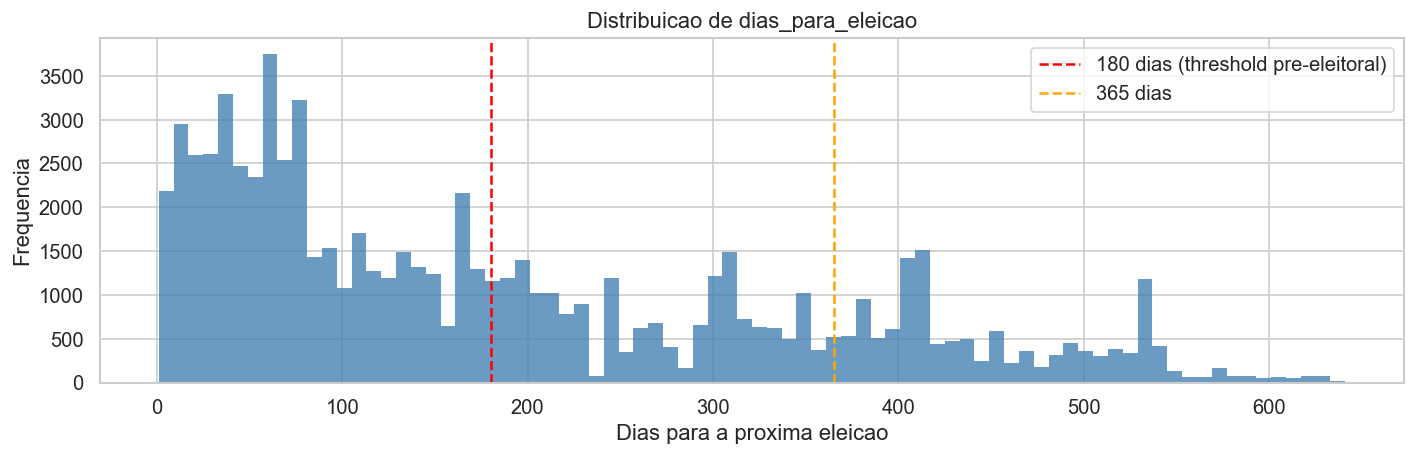

In [42]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(df['dias_para_eleicao'], bins=80, color='steelblue', alpha=0.8, edgecolor='none')
ax.axvline(180, color='red', linestyle='--', label='180 dias (threshold pre-eleitoral)')
ax.axvline(365, color='orange', linestyle='--', label='365 dias')
ax.set_title('Distribuicao de dias_para_eleicao')
ax.set_xlabel('Dias para a proxima eleicao')
ax.set_ylabel('Frequencia')
ax.legend()
plt.tight_layout()
plt.show()

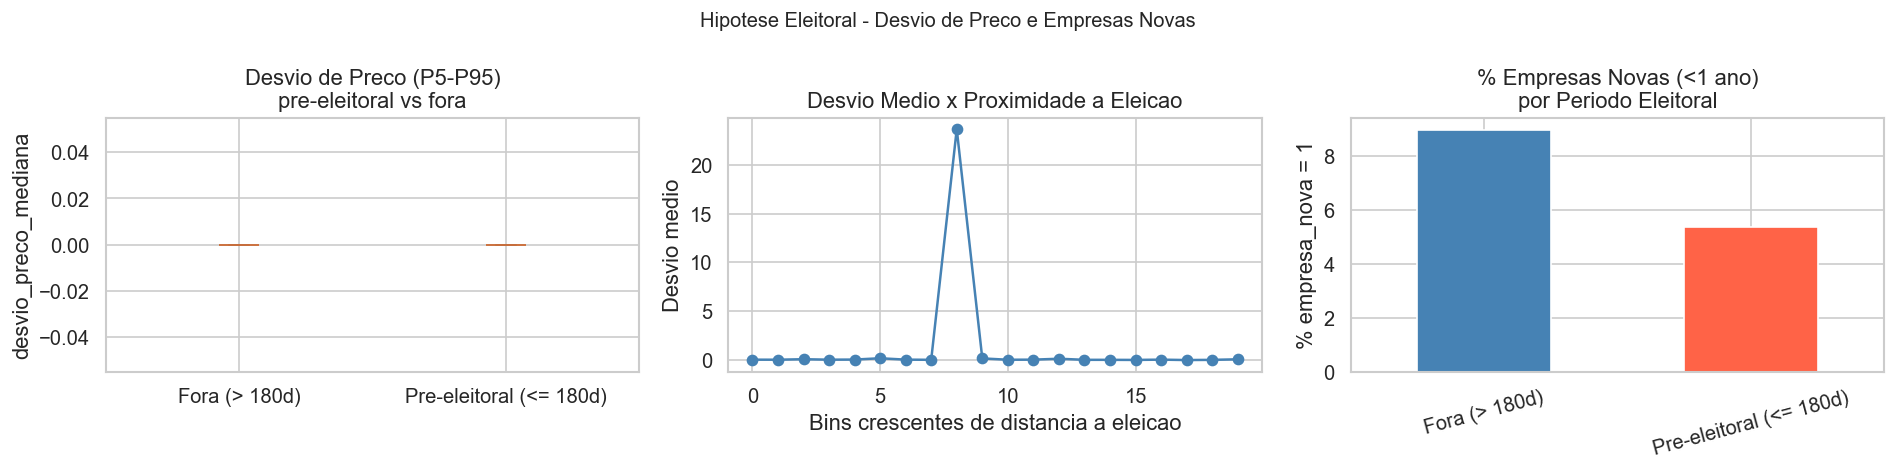

Mann-Whitney U (pre-eleitoral vs fora):
  U = 697543486  |  p-value = 0.0001
  Mediana fora:          0.0000
  Mediana pre-eleitoral: 0.0000


In [43]:
labels_eleit = {0: 'Fora (> 180d)', 1: 'Pre-eleitoral (<= 180d)'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Boxplot desvio x pre_eleitoral_180d
grupos = df.groupby('pre_eleitoral_180d')['desvio_preco_mediana']
data_box = [grupos.get_group(k) for k in [0, 1]]
bp = axes[0].boxplot(data_box, labels=[labels_eleit[0], labels_eleit[1]],
                     whis=[5, 95], showfliers=False, patch_artist=True)
for patch, color in zip(bp['boxes'], ['lightblue', 'tomato']):
    patch.set_facecolor(color)
axes[0].set_title('Desvio de Preco (P5-P95)\npre-eleitoral vs fora')
axes[0].set_ylabel('desvio_preco_mediana')

# Desvio medio em bins de dias_para_eleicao
df['dias_bin'] = pd.cut(df['dias_para_eleicao'], bins=20)
desvio_por_dias = df.groupby('dias_bin', observed=True)['desvio_preco_mediana'].mean()
axes[1].plot(range(len(desvio_por_dias)), desvio_por_dias.values,
             marker='o', color='steelblue', linewidth=1.5)
axes[1].set_title('Desvio Medio x Proximidade a Eleicao')
axes[1].set_xlabel('Bins crescentes de distancia a eleicao')
axes[1].set_ylabel('Desvio medio')

# Taxa de empresa nova x pre-eleitoral
taxa_nova_eleit = df.groupby('pre_eleitoral_180d')['empresa_nova'].mean() * 100
taxa_nova_eleit.index = [labels_eleit[0], labels_eleit[1]]
taxa_nova_eleit.plot(kind='bar', ax=axes[2], color=['steelblue', 'tomato'], rot=15)
axes[2].set_title('% Empresas Novas (<1 ano)\npor Periodo Eleitoral')
axes[2].set_ylabel('% empresa_nova = 1')

plt.suptitle('Hipotese Eleitoral - Desvio de Preco e Empresas Novas', fontsize=12)
plt.tight_layout()
plt.show()

# Teste estatistico Mann-Whitney U
g0 = df.loc[df['pre_eleitoral_180d'] == 0, 'desvio_preco_mediana']
g1 = df.loc[df['pre_eleitoral_180d'] == 1, 'desvio_preco_mediana']
stat_u, pval_u = stats.mannwhitneyu(g0, g1, alternative='two-sided')
print('Mann-Whitney U (pre-eleitoral vs fora):')
print(f'  U = {stat_u:.0f}  |  p-value = {pval_u:.4f}')
print(f'  Mediana fora:          {g0.median():.4f}')
print(f'  Mediana pre-eleitoral: {g1.median():.4f}')

---
### 8. Análise Geográfica

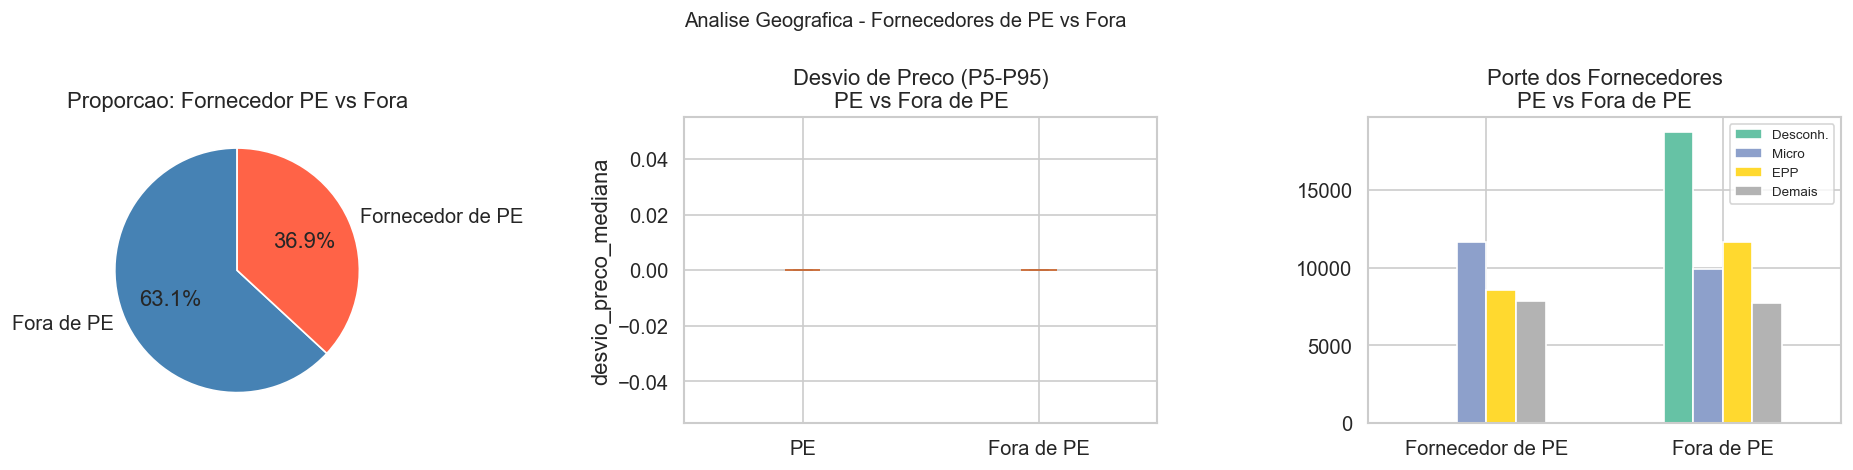

Mediana desvio PE:      0.0000
Mediana desvio Fora PE: 0.0000
Mann-Whitney p-value:   0.0059


In [44]:
fora_pe_labels = {0: 'Fornecedor de PE', 1: 'Fora de PE'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

fora_pe_counts = df['fornecedor_fora_pe'].value_counts()
axes[0].pie(fora_pe_counts.values,
            labels=[fora_pe_labels[k] for k in fora_pe_counts.index],
            autopct='%1.1f%%', colors=['steelblue', 'tomato'], startangle=90)
axes[0].set_title('Proporcao: Fornecedor PE vs Fora')

g_pe   = df.loc[df['fornecedor_fora_pe'] == 0, 'desvio_preco_mediana']
g_fora = df.loc[df['fornecedor_fora_pe'] == 1, 'desvio_preco_mediana']
bp = axes[1].boxplot([g_pe, g_fora], labels=['PE', 'Fora de PE'],
                     whis=[5,95], showfliers=False, patch_artist=True)
for patch, c in zip(bp['boxes'], ['lightblue', 'tomato']):
    patch.set_facecolor(c)
axes[1].set_title('Desvio de Preco (P5-P95)\nPE vs Fora de PE')
axes[1].set_ylabel('desvio_preco_mediana')

porte_map2 = {0: 'Desconh.', 1: 'Micro', 2: 'EPP', 3: 'Demais'}
porte_geo = df.groupby(['fornecedor_fora_pe', 'porte']).size().unstack(fill_value=0)
porte_geo.index = [fora_pe_labels[k] for k in porte_geo.index]
porte_geo.columns = [porte_map2.get(c, str(c)) for c in porte_geo.columns]
porte_geo.plot(kind='bar', ax=axes[2], rot=0, colormap='Set2')
axes[2].set_title('Porte dos Fornecedores\nPE vs Fora de PE')
axes[2].legend(fontsize=8)

plt.suptitle('Analise Geografica - Fornecedores de PE vs Fora', fontsize=12)
plt.tight_layout()
plt.show()

print(f'Mediana desvio PE:      {g_pe.median():.4f}')
print(f'Mediana desvio Fora PE: {g_fora.median():.4f}')
stat_geo, pval_geo = stats.mannwhitneyu(g_pe, g_fora, alternative='two-sided')
print(f'Mann-Whitney p-value:   {pval_geo:.4f}')

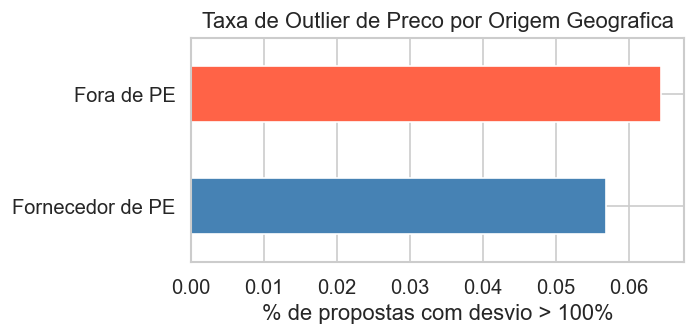

In [45]:
taxa_outlier_geo = df.groupby('fornecedor_fora_pe')['outlier_preco'].mean() * 100
taxa_outlier_geo.index = [fora_pe_labels[k] for k in taxa_outlier_geo.index]

fig, ax = plt.subplots(figsize=(6, 3))
taxa_outlier_geo.plot(kind='barh', ax=ax, color=['steelblue', 'tomato'])
ax.set_xlabel('% de propostas com desvio > 100%')
ax.set_title('Taxa de Outlier de Preco por Origem Geografica')
plt.tight_layout()
plt.show()

---
### 9. Análise por Modalidade Licitatória

A modalidade licitatória determina o rito processual e o nível de competição esperado.
No dataset, `modalidadeNome` foi label-encoded no NB06. Esta seção analisa:

1. **Volume por modalidade**: quais modalidades concentram mais propostas?
2. **Desvio de preço por modalidade**: modalidades com menos concorrência tendem a ter
   maior sobrepreço?
3. **Fornecedor único por modalidade**: a taxa de `fornecedor_unico` varia por modalidade?
   Modalidades de Dispensa e Inexigibilidade têm naturalmente alta taxa, mas em Pregão
   Eletrônico é um sinal de alerta.
4. **Heatmap de risco**: visualização cruzada de 5 indicadores de risco por modalidade,
   normalizada por coluna para comparação relativa entre modalidades.

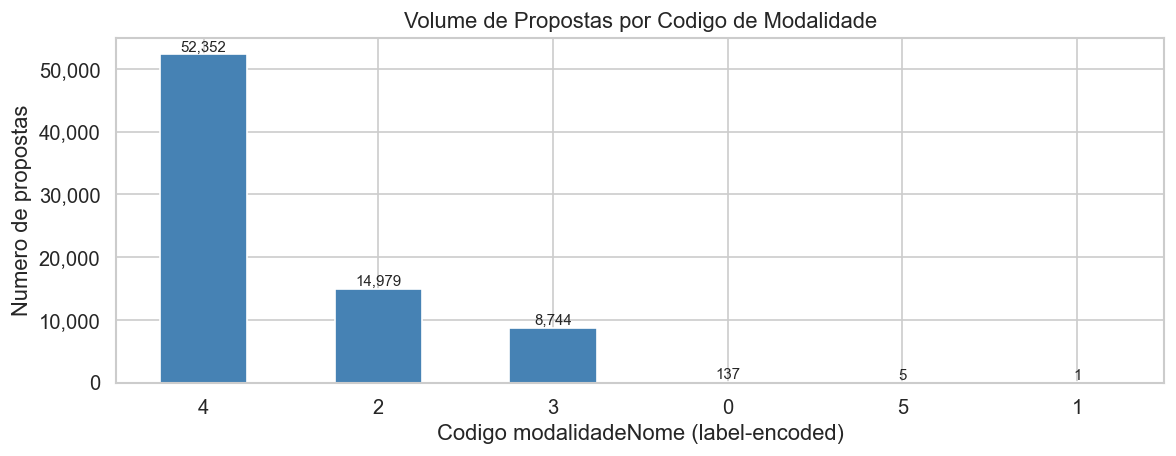

In [46]:
modal_counts = df['modalidadeNome'].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
modal_counts.plot(kind='bar', ax=ax, color='steelblue', rot=0)
ax.set_title('Volume de Propostas por Codigo de Modalidade')
ax.set_xlabel('Codigo modalidadeNome (label-encoded)')
ax.set_ylabel('Numero de propostas')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

In [47]:
modal_stats = df.groupby('modalidadeNome').agg(
    n_propostas=('desvio_preco_mediana', 'count'),
    desvio_mediana=('desvio_preco_mediana', 'median'),
    desvio_media=('desvio_preco_mediana', 'mean'),
    taxa_outlier=('outlier_preco', 'mean'),
    taxa_forn_unico=('fornecedor_unico', 'mean'),
    taxa_empresa_nova=('empresa_nova', 'mean'),
    taxa_fora_pe=('fornecedor_fora_pe', 'mean')
).sort_values('n_propostas', ascending=False)

modal_stats[['taxa_outlier','taxa_forn_unico','taxa_empresa_nova','taxa_fora_pe']] *= 100

print('Estatisticas por Modalidade:')
modal_stats.round(3)

Estatisticas por Modalidade:


,n_propostas,desvio_mediana,desvio_media,taxa_outlier,taxa_forn_unico,taxa_empresa_nova,taxa_fora_pe
modalidadeNome,,,,,,,
4,52352,0.0,0.848,0.019,94.277,6.493,60.926
2,14979,0.0,0.051,0.167,80.052,11.843,53.742
3,8744,0.0,0.148,0.137,79.323,0.480,92.578
0,137,0.0,0.156,0.000,78.832,0.730,42.336
5,5,0.0,0.000,0.000,100.000,0.000,100.000
1,1,0.0,0.000,0.000,100.000,0.000,100.000


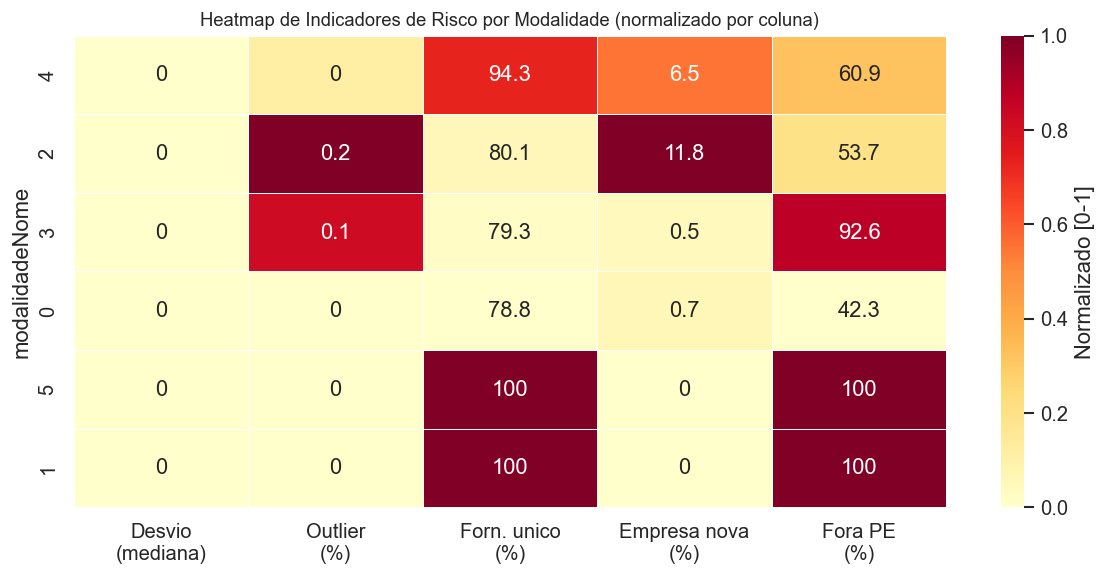

In [48]:
risk_cols   = ['desvio_mediana','taxa_outlier','taxa_forn_unico','taxa_empresa_nova','taxa_fora_pe']
risk_labels = ['Desvio\n(mediana)','Outlier\n(%)','Forn. unico\n(%)','Empresa nova\n(%)','Fora PE\n(%)']

risk_df   = modal_stats[risk_cols].copy()
risk_norm = (risk_df - risk_df.min()) / (risk_df.max() - risk_df.min() + 1e-9)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(risk_norm, annot=risk_df.round(1), fmt='g',
            cmap='YlOrRd', ax=ax, xticklabels=risk_labels,
            linewidths=0.5, cbar_kws={'label': 'Normalizado [0-1]'})
ax.set_title('Heatmap de Indicadores de Risco por Modalidade (normalizado por coluna)', fontsize=11)
plt.tight_layout()
plt.show()

---
### 10. Correlações entre Features

O mapa de correlações permite identificar:
1. **Redundâncias**: features altamente correlacionadas que carregam informação similar
   e podem prejudicar modelos de distância (LOF, One-Class SVM com kernel RBF).
2. **Relações inesperadas**: correlações que podem gerar confusão na interpretação dos
   scores de anomalia.
3. **Features independentes**: features com baixa correlação entre si têm maior poder
   discriminatório quando combinadas.

Usa Spearman (não Pearson) porque as distribuições são fortemente assimétricas e não-normais.
Features de identificação são excluídas da análise.

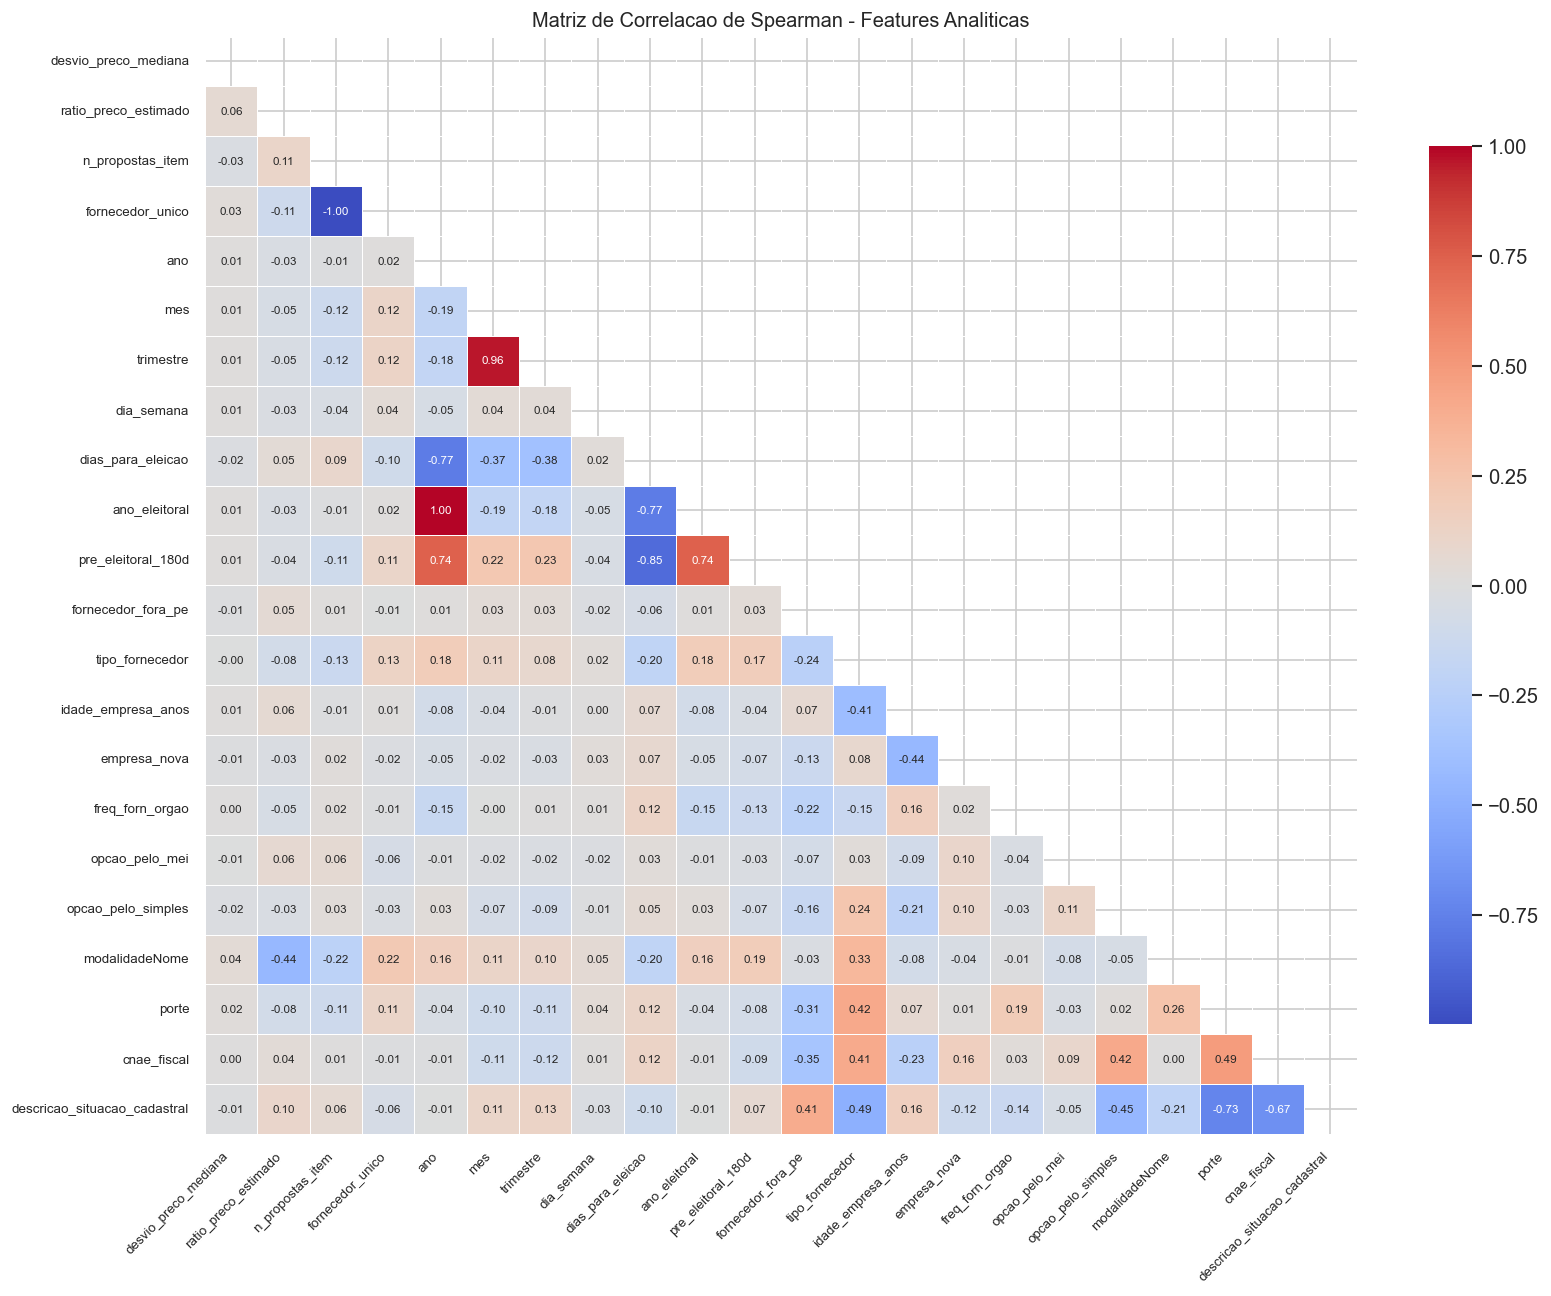

In [49]:
id_cols = ['orgaoEntidadeCnpj', 'cnpj_forn_norm', 'anoCompraPncp',
           'sequencialCompraPncp', 'numeroItem', 'ano_mes', 'dias_bin', 'outlier_preco']

feat_cols = [c for c in df.columns if c not in id_cols]
corr = df[feat_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.3, annot_kws={'size': 7},
            cbar_kws={'shrink': 0.8})
ax.set_title('Matriz de Correlacao de Spearman - Features Analiticas', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

In [50]:
corr_pairs = corr.unstack().reset_index()
corr_pairs.columns = ['feat_a', 'feat_b', 'r']
corr_pairs = corr_pairs[
    (corr_pairs['feat_a'] < corr_pairs['feat_b']) &
    (corr_pairs['r'].abs() > 0.5)
].sort_values('r', key=abs, ascending=False)

if len(corr_pairs) == 0:
    print('Nenhum par com |r| > 0.5 - sem redundancias preocupantes.')
else:
    print('Pares com |r_spearman| > 0.5 (atencao para redundancia):')
    print(corr_pairs.to_string(index=False))

Pares com |r_spearman| > 0.5 (atencao para redundancia):
                      feat_a                       feat_b         r
                         ano                ano_eleitoral  1.000000
            fornecedor_unico             n_propostas_item -0.998526
                         mes                    trimestre  0.964504
           dias_para_eleicao           pre_eleitoral_180d -0.851576
                         ano            dias_para_eleicao -0.774870
               ano_eleitoral            dias_para_eleicao -0.774870
                         ano           pre_eleitoral_180d  0.743485
               ano_eleitoral           pre_eleitoral_180d  0.743485
descricao_situacao_cadastral                        porte -0.731767
                 cnae_fiscal descricao_situacao_cadastral -0.672465


---
### 11. Síntese dos Achados da EDA

Esta seção consolida os principais achados para orientar as decisões de modelagem no NB08.
Os achados são apresentados por dimensão analítica.

**Nota**: esta célula usa variáveis (`pval_u`, `pval_geo`, `g_pe`, `g_fora`) calculadas
nas seções 7 e 8. Execute o notebook de cima para baixo antes desta célula.

In [51]:
print('=' * 65)
print('SINTESE DA EDA - NB07')
print('=' * 65)

print('\n--- Dataset ---')
print(f'Total de propostas:             {len(df):>10,}')
n_orgaos = df['orgaoEntidadeCnpj'].nunique()
n_forn   = df['cnpj_forn_norm'].nunique()
print(f'Orgaos compradores:             {n_orgaos:>10,}')
print(f'Fornecedores unicos:            {n_forn:>10,}')
print(f'Periodo coberto:                2023 - 2024')

print('\n--- Preco ---')
med_glob = df['desvio_preco_mediana'].median()
mean_glob = df['desvio_preco_mediana'].mean()
pct_50  = (df['desvio_preco_mediana'] > 0.5).mean() * 100
pct_100 = (df['desvio_preco_mediana'] > 1.0).mean() * 100
pct_teto = (df['ratio_preco_estimado'] > 1.0).mean() * 100
print(f'Desvio mediano global:          {med_glob:>10.4f}')
print(f'Desvio medio global:            {mean_glob:>10.4f}')
print(f'Propostas com desvio > 50%:     {pct_50:>9.1f}%')
print(f'Propostas com desvio > 100%:    {pct_100:>9.1f}%')
print(f'Propostas acima do teto:        {pct_teto:>9.1f}%')

print('\n--- Eleitoral ---')
pct_pre  = df['pre_eleitoral_180d'].mean() * 100
d_pre_v  = df.loc[df['pre_eleitoral_180d']==1,'desvio_preco_mediana'].median()
d_fora_v = df.loc[df['pre_eleitoral_180d']==0,'desvio_preco_mediana'].median()
print(f'Propostas pre-eleitorais <=180d: {pct_pre:>9.1f}%')
print(f'Desvio mediano pre-eleitoral:   {d_pre_v:>10.4f}')
print(f'Desvio mediano fora eleitoral:  {d_fora_v:>10.4f}')
print(f'p-value Mann-Whitney:           {pval_u:>10.4f}')

print('\n--- Geografico ---')
pct_fora_pe = df['fornecedor_fora_pe'].mean() * 100
print(f'Fornecedores fora de PE:        {pct_fora_pe:>9.1f}%')
print(f'Desvio mediano forn. PE:        {g_pe.median():>10.4f}')
print(f'Desvio mediano forn. fora PE:   {g_fora.median():>10.4f}')
print(f'p-value Mann-Whitney:           {pval_geo:>10.4f}')

print('\n--- Perfil de Fornecedores ---')
pct_unico  = df['fornecedor_unico'].mean() * 100
pct_fisica = (df['tipo_fornecedor']==0).mean() * 100
pct_nova   = df['empresa_nova'].mean() * 100
pct_micro  = (df['porte']==1).mean() * 100
print(f'Fornecedor unico (item):        {pct_unico:>9.1f}%')
print(f'Pessoas fisicas:                {pct_fisica:>9.1f}%')
print(f'Empresas novas (<1 ano):        {pct_nova:>9.1f}%')
print(f'Micro empresas (porte=1):       {pct_micro:>9.1f}%')

print('\n' + '=' * 65)

SINTESE DA EDA - NB07

--- Dataset ---
Total de propostas:                 76,218
Orgaos compradores:                    103
Fornecedores unicos:                 9,447
Periodo coberto:                2023 - 2024

--- Preco ---
Desvio mediano global:              0.0000
Desvio medio global:                0.6097
Propostas com desvio > 50%:           1.4%
Propostas com desvio > 100%:          0.1%
Propostas acima do teto:              0.0%

--- Eleitoral ---
Propostas pre-eleitorais <=180d:      59.1%
Desvio mediano pre-eleitoral:       0.0000
Desvio mediano fora eleitoral:      0.0000
p-value Mann-Whitney:               0.0001

--- Geografico ---
Fornecedores fora de PE:             63.1%
Desvio mediano forn. PE:            0.0000
Desvio mediano forn. fora PE:       0.0000
p-value Mann-Whitney:               0.0059

--- Perfil de Fornecedores ---
Fornecedor unico (item):             89.7%
Pessoas fisicas:                      8.9%
Empresas novas (<1 ano):              6.8%
Micro empresa

In [52]:
features_modelo = [
    'desvio_preco_mediana', 'ratio_preco_estimado', 'fornecedor_unico',
    'dias_para_eleicao', 'pre_eleitoral_180d',
    'fornecedor_fora_pe',
    'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova',
    'freq_forn_orgao', 'opcao_pelo_mei', 'opcao_pelo_simples',
    'modalidadeNome', 'porte', 'cnae_fiscal',
    'ano', 'mes', 'dia_semana'
]

ausentes = [f for f in features_modelo if f not in df.columns]
if ausentes:
    print(f'AVISO: features ausentes no dataset: {ausentes}')
else:
    print(f'OK - {len(features_modelo)} features de modelagem verificadas.')

shape_modelo = df[features_modelo].shape
print(f'\nShape do subset de modelagem: {shape_modelo}')

OK - 18 features de modelagem verificadas.

Shape do subset de modelagem: (76218, 18)
